# Model training

Trains a pretrained ResNet18 on the two training sets produced by `preprocessing.ipynb`:

- **regular**: the reduced training set, no augmentation (reference condition)
- **augmented**: the same images plus one augmented copy of each (controlled comparison)

Everything else is identical between the two conditions: model, optimiser, learning rate, number of training steps, validation set and test set.
Each condition is trained with 5 random seeds.

Outputs:
- `results/<condition>_seed<n>.json`: training history and test scores for each run
- `results/<condition>_seed<n>_test_predictions.csv`: per-image test predictions, for evaluation
- `results/summary.csv`: mean and standard deviation per condition
- `models/<condition>_seed<n>.pt`: trained weights (not committed)

Finished runs are skipped, so if the notebook is stopped part way, **Run All** continues where it left off.

In [1]:
#Imports
import copy
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

In [2]:
#Settings
SEEDS = [0, 1, 2, 3, 4]               # 5 runs per condition
CONDITIONS = ["regular", "augmented"]

BATCH_SIZE = 32
LEARNING_RATE = 1e-4                  # small, so the pretrained weights are adjusted gently
WEIGHT_DECAY = 1e-4

# Both conditions get the same number of weight updates. The augmented set has
# twice as many images, so counting epochs would give it twice the training.
MAX_STEPS = 600
EVAL_EVERY = 50                       # check the validation set every 50 steps
PATIENCE = 4                          # stop after 4 checks with no val-loss improvement

NUM_WORKERS = 4
torch.set_num_threads(os.cpu_count())

In [3]:
# Paths
PROJECT_DIR = Path.cwd()

data_path = PROJECT_DIR / "processed_data"
results_path = PROJECT_DIR / "results"
models_path = PROJECT_DIR / "models"

assert data_path.exists(), (
    f"Processed data not found at: {data_path}. Run preprocessing.ipynb first."
)

results_path.mkdir(exist_ok=True)
models_path.mkdir(exist_ok=True)

print("Data:", data_path.relative_to(PROJECT_DIR))
print("Results:", results_path.relative_to(PROJECT_DIR))
print("Models:", models_path.relative_to(PROJECT_DIR))

Data: processed_data
Results: results
Models: models


In [4]:
#Load data
# Images are already 224 x 224 from preprocessing. Convert to tensors and
# normalise with the ImageNet statistics the pretrained ResNet18 was trained on.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


def load_split(condition, split):
    return datasets.ImageFolder(
        root=data_path / condition / split,
        transform=transform
    )


# Validation and test images are identical in both conditions, so load them once
val_dataset = load_split("regular", "val")
test_dataset = load_split("regular", "test")

classes = test_dataset.classes

print("Classes:", classes)
for condition in CONDITIONS:
    print(f"{condition} train:", len(load_split(condition, "train")))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Classes: ['jerry', 'tom', 'tom_jerry_0', 'tom_jerry_1']
regular train: 1369
augmented train: 2738
Validation: 1370
Test: 2739


In [5]:
#Model
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def build_model():
    # ResNet18 with ImageNet weights; the 1000-class output layer is replaced
    # with a new 4-class layer. All layers are trained (fine-tuning).
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(classes))
    return model


def build_optimizer(model):
    # Weight decay on conv/linear weights only; biases and BatchNorm get none
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]

    return torch.optim.AdamW([
        {"params": decay, "weight_decay": WEIGHT_DECAY},
        {"params": no_decay, "weight_decay": 0.0}
    ], lr=LEARNING_RATE)


criterion = nn.CrossEntropyLoss()

In [6]:
#Evaluation
@torch.no_grad()
def evaluate(model, loader):
    # Returns mean cross-entropy, accuracy, true labels and predicted probabilities
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probs = []

    for images, labels in loader:
        logits = model(images)
        total_loss += criterion(logits, labels).item() * len(labels)
        all_labels.append(labels)
        all_probs.append(torch.softmax(logits, dim=1))

    labels = torch.cat(all_labels)
    probs = torch.cat(all_probs)
    accuracy = (probs.argmax(dim=1) == labels).float().mean().item()

    return total_loss / len(labels), accuracy, labels, probs

In [7]:
#Training
def train_one_run(condition, seed):

    set_seed(seed)

    train_loader = DataLoader(
        load_split(condition, "train"),
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=NUM_WORKERS
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=64,
        num_workers=NUM_WORKERS
    )

    model = build_model()
    optimizer = build_optimizer(model)

    history = []
    best_val_loss = float("inf")
    best_state = None
    best_step = 0
    checks_without_improvement = 0

    step = 0
    running_loss = 0.0
    batches = iter(train_loader)

    while step < MAX_STEPS:

        # Loop over the training set as many times as needed to reach MAX_STEPS
        try:
            images, labels = next(batches)
        except StopIteration:
            batches = iter(train_loader)
            images, labels = next(batches)

        model.train()
        loss = criterion(model(images), labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        step += 1
        running_loss += loss.item()

        if step % EVAL_EVERY == 0:

            val_loss, val_accuracy, _, _ = evaluate(model, val_loader)

            history.append({
                "step": step,
                "train_loss": running_loss / EVAL_EVERY,
                "val_loss": val_loss,
                "val_accuracy": val_accuracy
            })
            running_loss = 0.0

            print(
                f"  step {step:4d} | "
                f"train loss {history[-1]['train_loss']:.3f} | "
                f"val loss {val_loss:.3f} | "
                f"val acc {val_accuracy:.3f}"
            )

            # Early stopping: keep the checkpoint with the lowest validation loss
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                best_step = step
                checks_without_improvement = 0
            else:
                checks_without_improvement += 1

                if checks_without_improvement >= PATIENCE:
                    print(f"  Early stopping at step {step}")
                    break

    model.load_state_dict(best_state)

    return model, history, best_step, best_val_loss

In [8]:
#Run all experiments
# The test set is only used here, once per run, after training has finished.
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    num_workers=NUM_WORKERS
)

for condition in CONDITIONS:

    for seed in SEEDS:

        run_name = f"{condition}_seed{seed}"
        result_file = results_path / f"{run_name}.json"

        if result_file.exists():
            print(f"Skipping {run_name}: already done")
            continue

        print(f"\nTraining {run_name}")
        start = time.time()

        model, history, best_step, best_val_loss = train_one_run(condition, seed)

        test_loss, test_accuracy, labels, probs = evaluate(model, test_loader)
        predicted = probs.argmax(dim=1)

        torch.save(model.state_dict(), models_path / f"{run_name}.pt")

        #Per-image test predictions, for the evaluation stage
        predictions = pd.DataFrame(
            probs.numpy(),
            columns=[f"prob_{c}" for c in classes]
        )
        predictions.insert(0, "image", [
            str(Path(path).relative_to(PROJECT_DIR)) for path, _ in test_dataset.samples
        ])
        predictions.insert(1, "label", [classes[i] for i in labels])
        predictions.insert(2, "predicted", [classes[i] for i in predicted])
        predictions.to_csv(
            results_path / f"{run_name}_test_predictions.csv",
            index=False
        )

        result = {
            "condition": condition,
            "seed": seed,
            "best_step": best_step,
            "best_val_loss": best_val_loss,
            "test_loss": test_loss,
            "test_accuracy": test_accuracy,
            "minutes": (time.time() - start) / 60,
            "history": history
        }
        result_file.write_text(json.dumps(result, indent=2))

        print(
            f"Done {run_name}: test acc {test_accuracy:.3f}, "
            f"test loss {test_loss:.3f}, {result['minutes']:.1f} min"
        )


Training regular_seed0
  step   50 | train loss 0.576 | val loss 1.300 | val acc 0.581
  step  100 | train loss 0.097 | val loss 1.208 | val acc 0.593
  step  150 | train loss 0.036 | val loss 1.408 | val acc 0.594
  step  200 | train loss 0.020 | val loss 1.409 | val acc 0.597
  step  250 | train loss 0.015 | val loss 1.472 | val acc 0.593
  step  300 | train loss 0.008 | val loss 1.402 | val acc 0.596
  Early stopping at step 300
Done regular_seed0: test acc 0.581, test loss 1.273, 22.9 min

Training regular_seed1
  step   50 | train loss 0.554 | val loss 1.135 | val acc 0.595
  step  100 | train loss 0.103 | val loss 1.027 | val acc 0.654
  step  150 | train loss 0.037 | val loss 1.079 | val acc 0.664
  step  200 | train loss 0.026 | val loss 1.084 | val acc 0.661
  step  250 | train loss 0.015 | val loss 1.327 | val acc 0.608
  step  300 | train loss 0.012 | val loss 1.362 | val acc 0.625
  Early stopping at step 300
Done regular_seed1: test acc 0.627, test loss 1.081, 23.6 min

T

In [9]:
#Summary
runs = pd.DataFrame([
    json.loads((results_path / f"{c}_seed{s}.json").read_text())
    for c in CONDITIONS
    for s in SEEDS
]).drop(columns="history")

print(runs[["condition", "seed", "best_step", "test_accuracy", "test_loss"]])

summary = runs.groupby("condition", sort=False)[["test_accuracy", "test_loss"]].agg(["mean", "std"])
summary.to_csv(results_path / "summary.csv")

print("\nMean and standard deviation over seeds")
print(summary)

   condition  seed  best_step  test_accuracy  test_loss
0    regular     0        100       0.580869   1.273263
1    regular     1        100       0.627236   1.081218
2    regular     2        100       0.564074   1.334132
3    regular     3        150       0.610442   1.286977
4    regular     4         50       0.592917   1.214620
5  augmented     0         50       0.556407   1.390262
6  augmented     1        100       0.617014   1.116137
7  augmented     2        100       0.605695   1.240765
8  augmented     3        300       0.635999   1.351901
9  augmented     4        150       0.590361   1.293547

Mean and standard deviation over seeds
          test_accuracy           test_loss          
                   mean       std      mean       std
condition                                            
regular        0.595108  0.024688  1.238042  0.097482
augmented      0.601095  0.030021  1.278522  0.107110


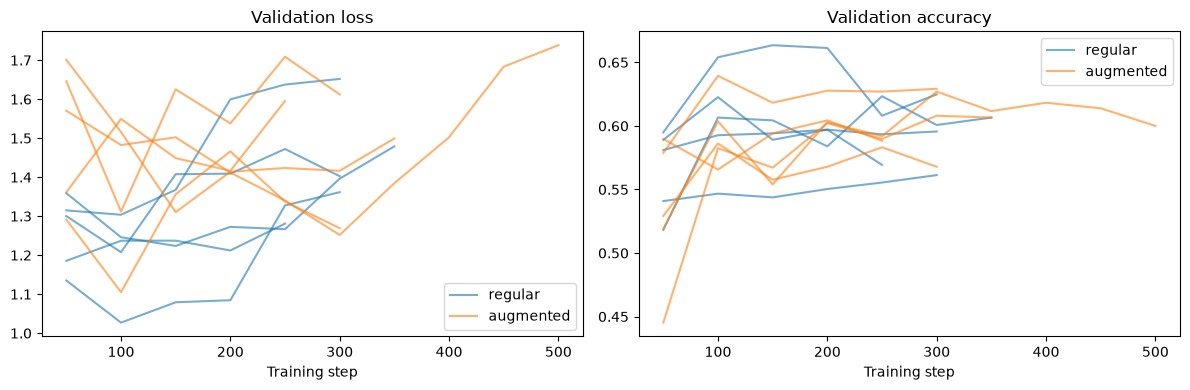

In [10]:
#Validation curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for condition, colour in zip(CONDITIONS, ["tab:blue", "tab:orange"]):
    for seed in SEEDS:
        history = pd.DataFrame(
            json.loads((results_path / f"{condition}_seed{seed}.json").read_text())["history"]
        )
        label = condition if seed == SEEDS[0] else None
        axes[0].plot(history["step"], history["val_loss"], color=colour, alpha=0.6, label=label)
        axes[1].plot(history["step"], history["val_accuracy"], color=colour, alpha=0.6, label=label)

axes[0].set_title("Validation loss")
axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Training step")
    ax.legend()

plt.tight_layout()
plt.show()

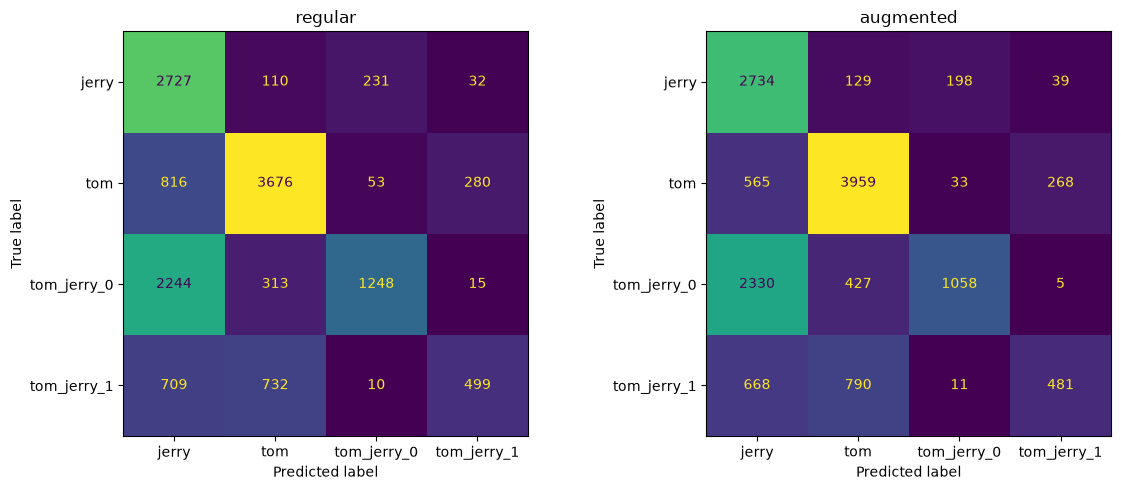

In [11]:
#Confusion matrices (test set, all seeds combined)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, condition in zip(axes, CONDITIONS):

    predictions = pd.concat([
        pd.read_csv(results_path / f"{condition}_seed{seed}_test_predictions.csv")
        for seed in SEEDS
    ])

    matrix = confusion_matrix(
        predictions["label"],
        predictions["predicted"],
        labels=classes
    )

    ConfusionMatrixDisplay(matrix, display_labels=classes).plot(ax=ax, colorbar=False)
    ax.set_title(condition)

plt.tight_layout()
plt.show()